# Judge accuracy (Alt-Test)

Same scoring path as `uv run run_judges.py --accuracy-only`: each judge is scored against the three human ratings with the [Alternative Annotator Test](https://arxiv.org/abs/2501.10970).

Headline number is **average advantage probability ρ** (chance the judge is as good as or better than a randomly chosen annotator). Winning rate **ω** uses ε = 0.15 and is secondary. **llm** / **hum** are leave-one-out agreement with the other two labelers.

Unparsed judge replies are **not** treated as an Incorrect verdict. They enter the Alt-Test as a label that matches neither human pass nor fail, so they count as disagreements. **parse** is the share of stored answers with a `pass`/`fail` verdict.

ρ intervals are 95% question-clustered bootstrap CIs. Charts omit prompt modes with no verdicts. Two extra no-gold branches come from `outputs/gemini-desc-judge/`: Gemini 3.7 Flash grades `judge_no_gt` from a clip caption instead of the audio (first caption, and best of ≤5 as an oracle upper bound).


In [17]:
from __future__ import annotations

import csv
import io
import json
import os
from pathlib import Path

os.environ["MPLBACKEND"] = "Agg"

import matplotlib

matplotlib.use("Agg", force=True)

from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import grader
from aggregate import DROPPED_MODEL_LABELS, is_dropped_model
from alt_test import (
    DEFAULT_EPSILON,
    MIN_HUMANS_PER_INSTANCE,
    compare_binary_judges,
    llm_annotation_from_entry,
    score_binary_judge,
)
from grader import (
    JUDGE_FORMATS,
    accuracy_mode_names,
    grade_mode_title,
    grade_prompt_names,
    judge_mode_bucket,
    parse_judge_key,
)
from mmar_common import write_json

plt.ioff()
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.axisbelow": True,
        "font.size": 11,
        "axes.titlesize": 13,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    }
)


def _show_figures(*_args, **_kwargs):
    for num in list(plt.get_fignums()):
        fig = plt.figure(num)
        buf = io.BytesIO()
        fig.savefig(buf, format="png")
        display(Image(data=buf.getvalue()))
        plt.close(fig)


plt.show = _show_figures

# Local copies of the scoring helpers in run_judges.py. Do not import that
# module: it talks to Modal at import time (volumes, secrets, image build).
REPO_ROOT = Path(grader.__file__).resolve().parent
PACK_NAME = "mmar-judging"
EXPORTS_DIR = REPO_ROOT / "exports"
LOCAL_PACK_DIR = REPO_ROOT / "outputs" / PACK_NAME
LABELS_CSV_NAME = "labels.csv"
ACCURACY_JSON_NAME = "judge_accuracy.json"
_judge_mode_bucket = judge_mode_bucket
_entry_correct = llm_annotation_from_entry


def _parse_ratings_cell(raw: object) -> dict[str, bool]:
    if isinstance(raw, (list, dict)):
        values = raw
    else:
        text = str(raw or "").strip()
        if not text:
            return {}
        try:
            values = json.loads(text)
        except json.JSONDecodeError:
            return {}
    if isinstance(values, list):
        items = ((str(index), item) for index, item in enumerate(values))
    elif isinstance(values, dict):
        items = ((str(annotator_id), item) for annotator_id, item in values.items())
    else:
        return {}
    out: dict[str, bool] = {}
    for annotator_id, item in items:
        if isinstance(item, bool):
            out[annotator_id] = item
        else:
            return {}
    return out


def load_pack_label_rows(labels_path: Path) -> list[dict]:
    rows: list[dict] = []
    with labels_path.open(encoding="utf-8", newline="") as handle:
        reader = csv.DictReader(handle)
        for raw in reader:
            qid = str(raw.get("question_id") or "").strip()
            model = str(raw.get("model_label") or "").strip()
            ratings_by_annotator = _parse_ratings_cell(raw.get("ratings"))
            if not qid or not model or not ratings_by_annotator:
                continue
            try:
                shot_index = int(raw.get("shot_index", 0))
            except (TypeError, ValueError):
                continue
            rows.append(
                {
                    "question_id": qid,
                    "model_label": model,
                    "shot_index": shot_index,
                    "ratings": list(ratings_by_annotator.values()),
                    "ratings_by_annotator": ratings_by_annotator,
                }
            )
    return rows


def labeled_question_ids(rows: list[dict]) -> list[str]:
    return list(dict.fromkeys(str(row["question_id"]) for row in rows))


def triple_labeled_rows(rows: list[dict]) -> list[dict]:
    return [
        row for row in rows if len(row.get("ratings") or []) >= MIN_HUMANS_PER_INSTANCE
    ]


def _load_predictions_by_id(path: Path) -> dict[str, dict]:
    by_id: dict[str, dict] = {}
    if not path.is_file():
        return by_id
    with path.open(encoding="utf-8") as handle:
        for line in handle:
            stripped = line.strip()
            if not stripped:
                continue
            record = json.loads(stripped)
            qid = str(record.get("id") or "").strip()
            if qid:
                by_id[qid] = record
    return by_id


def _shot_for_index(record: dict, shot_index: int) -> dict | None:
    for shot in record.get("shots") or []:
        try:
            if int(shot.get("shot_index", 0)) == shot_index:
                return shot
        except (TypeError, ValueError):
            continue
    return None


def _instance_id(row: dict) -> str:
    return f"{row['question_id']}\t{row['model_label']}\t{row['shot_index']}"


def _entry_parsed(entry: object) -> bool:
    if not isinstance(entry, dict):
        return False
    return str(entry.get("verdict") or "").strip().lower() in {"pass", "fail"}


def _parse_stats(
    samples: list[tuple[str, dict[str, bool], dict[str, dict] | None]],
    key: str,
) -> dict[str, int | float | None]:
    n_present = 0
    n_parsed = 0
    for _iid, _ratings, judges in samples:
        entry = (judges or {}).get(key)
        if not isinstance(entry, dict):
            continue
        n_present += 1
        if _entry_parsed(entry):
            n_parsed += 1
    n_unparsed = n_present - n_parsed
    return {
        "n_judge_answers": n_present,
        "n_parsed": n_parsed,
        "n_unparsed": n_unparsed,
        "parse_rate": (n_parsed / n_present) if n_present else None,
    }


def _score_judge_tables(
    samples: list[tuple[str, dict[str, bool], dict[str, dict] | None]],
    key_mode: dict[str, str],
    *,
    epsilon: float,
) -> dict[str, dict[str, dict]]:
    stats: dict[str, dict[str, dict]] = {name: {} for name in grade_prompt_names()}
    for key, mode in key_mode.items():
        instances = [
            (instance_id, ratings, _entry_correct((judges or {}).get(key)))
            for instance_id, ratings, judges in samples
        ]
        row = score_binary_judge(instances, epsilon=epsilon)
        row.update(_parse_stats(samples, key))
        stats.setdefault(mode, {})[key] = row
    return stats


def report_judge_accuracy(pack_dir: Path, *, epsilon: float = DEFAULT_EPSILON) -> dict:
    labels_path = pack_dir / LABELS_CSV_NAME
    if not labels_path.is_file():
        raise SystemExit(f"labels.csv not found at {labels_path}")
    rows = [
        row
        for row in triple_labeled_rows(load_pack_label_rows(labels_path))
        if not is_dropped_model(str(row.get("model_label") or ""))
    ]
    if not rows:
        raise SystemExit(
            f"No rows with ≥{MIN_HUMANS_PER_INSTANCE} human ratings in {labels_path}"
        )

    pred_cache: dict[str, dict[str, dict]] = {}
    samples: list[tuple[str, dict[str, bool], dict[str, dict] | None]] = []
    judge_keys: set[str] = set()
    for row in rows:
        model = row["model_label"]
        qid = row["question_id"]
        if model not in pred_cache:
            pred_cache[model] = _load_predictions_by_id(
                pack_dir / "models" / model / "predictions.jsonl"
            )
        record = pred_cache[model].get(qid)
        shot = _shot_for_index(record, row["shot_index"]) if record else None
        judges = None
        if shot is not None and isinstance(shot.get("judges"), dict):
            judges = {
                str(key): dict(entry)
                for key, entry in shot["judges"].items()
                if key and not is_dropped_model(str(key))
            }
            judge_keys.update(judges)
        samples.append(
            (_instance_id(row), dict(row["ratings_by_annotator"]), judges)
        )

    key_mode: dict[str, str] = {}
    for key in sorted(judge_keys):
        if is_dropped_model(key):
            continue
        sample_entry = next(
            (
                (judges or {}).get(key)
                for _iid, _ratings, judges in samples
                if judges and key in judges
            ),
            None,
        )
        mode = _judge_mode_bucket(
            key, sample_entry if isinstance(sample_entry, dict) else None
        )
        if mode is None:
            continue
        key_mode[key] = mode

    stats = _score_judge_tables(samples, key_mode, epsilon=epsilon)
    payload = {
        "pack": PACK_NAME,
        "labels_path": str(labels_path),
        "n_label_rows": len(rows),
        "n_questions": len(labeled_question_ids(rows)),
        "skipped_models": sorted(DROPPED_MODEL_LABELS),
        "epsilon": float(epsilon),
        "modes": accuracy_mode_names(stats),
    }
    for mode in payload["modes"]:
        payload[mode] = stats.get(mode) or {}
    dest = pack_dir / ACCURACY_JSON_NAME
    write_json(dest, payload)
    print(f"wrote {dest}")
    return payload

ImportError: cannot import name 'compare_binary_judges' from 'alt_test' (/home/jordan/tinkering/latent-reasoning/alt_test.py)

In [18]:
payload = report_judge_accuracy(LOCAL_PACK_DIR)
print(
    f"\npack={payload['pack']}  rows={payload['n_label_rows']}  "
    f"questions={payload['n_questions']}  ε={payload['epsilon']}"
)

wrote /home/jordan/tinkering/latent-reasoning/outputs/mmar-judging/judge_accuracy.json

pack=mmar-judging  rows=3834  questions=142  ε=0.15


In [ ]:
from cascade.run_gemini_desc_judge import (
    DEFAULT_OUT_DIR as DESC_JUDGE_DIR,
    DESC_MODE_BEST,
    DESC_MODE_FIRST,
    DESC_MODE_TITLES,
    desc_judge_accuracy_rows,
)

_MODE_PALETTE = (
    "#4C78A8",
    "#F58518",
    "#54A24B",
    "#72B7B2",
    "#E45756",
    "#B279A2",
    "#FF9DA6",
    "#9D755D",
    "#BAB0AC",
    "#F2CF5B",
)
PACK_MODE_ORDER = [m for m in grade_prompt_names() if payload.get(m)]
desc_grades = DESC_JUDGE_DIR / "grades.jsonl"
desc_df = (
    pd.DataFrame(
        desc_judge_accuracy_rows(
            DESC_JUDGE_DIR,
            epsilon=float(payload.get("epsilon") or 0.15),
        )
    )
    if desc_grades.is_file() and desc_grades.stat().st_size > 0
    else pd.DataFrame()
)
DESC_MODE_ORDER = [
    mode
    for mode in (DESC_MODE_FIRST, DESC_MODE_BEST)
    if not desc_df.empty and mode in set(desc_df["mode"])
]
MODE_ORDER = PACK_MODE_ORDER + DESC_MODE_ORDER
MODE_COLORS = {
    name: _MODE_PALETTE[i % len(_MODE_PALETTE)]
    for i, name in enumerate(list(grade_prompt_names()) + DESC_MODE_ORDER)
}

# X-axis labels match the JUDGE_FORMATS comments in grader.py:
# style (Discretionary / Neutral / Strict), gold, audio.
_STYLE_RANK = {"Discretionary": 0, "Neutral": 1, "Strict": 2}
_GOLD_RANK = {"With GT": 0, "No GT": 1}
_AUDIO_RANK = {"With Audio": 0, "No Audio": 1}


def format_properties(mode: str) -> tuple[str, str, str] | None:
    """(style, gold, audio) for a JUDGE_FORMATS key; None for caption/cascade."""
    fmt = JUDGE_FORMATS.get(mode)
    if fmt is None:
        return None
    if mode.startswith("judge_"):
        style = "Discretionary"
    elif mode.startswith("neutral_"):
        style = "Neutral"
    elif mode in {"with_gt", "with_gt_with_audio", "free"}:
        style = "Strict"
    else:
        return None
    gold = "With GT" if fmt.include_gold else "No GT"
    audio = "With Audio" if fmt.audio_included else "No Audio"
    return (style, gold, audio)


def format_axis_label(mode: str) -> str:
    props = format_properties(mode)
    if props is None:
        return mode_title(mode)
    return "\n".join(props)


def _format_sort_key(mode: str) -> tuple[int, int, int, str]:
    props = format_properties(mode)
    if props is None:
        return (99, 99, 99, mode)
    style, gold, audio = props
    return (
        _STYLE_RANK.get(style, 99),
        _GOLD_RANK.get(gold, 99),
        _AUDIO_RANK.get(audio, 99),
        mode,
    )


HEATMAP_MODE_ORDER = sorted(
    [m for m in PACK_MODE_ORDER if format_properties(m) is not None],
    key=_format_sort_key,
)


def flatten_accuracy(payload: dict) -> pd.DataFrame:
    rows = []
    for mode in PACK_MODE_ORDER:
        by_judge = payload.get(mode) or {}
        if not isinstance(by_judge, dict) or not by_judge:
            continue
        fmt = JUDGE_FORMATS.get(mode)
        for key, stats in sorted(by_judge.items()):
            parsed = parse_judge_key(key)
            model = parsed.get("model") or key
            prompt = parsed.get("prompt") or mode
            rows.append(
                {
                    "key": key,
                    "model": model,
                    "prompt": prompt,
                    "mode": mode,
                    "mode_title": grade_mode_title(mode),
                    "sees_gold": None if fmt is None else bool(fmt.include_gold),
                    "hears_audio": None if fmt is None else bool(fmt.audio_included),
                    "n": stats.get("n"),
                    "n_missing": stats.get("n_missing"),
                    "n_unparsed": stats.get("n_unparsed"),
                    "parse_rate": stats.get("parse_rate"),
                    "n_skipped_lt3": stats.get("n_skipped_lt3"),
                    "rho": stats.get("advantage_prob"),
                    "rho_lo": stats.get("advantage_prob_ci_low"),
                    "rho_hi": stats.get("advantage_prob_ci_high"),
                    "llm": stats.get("loo_agree_judge"),
                    "hum": stats.get("loo_agree_human"),
                    "omega": stats.get("winning_rate"),
                    "passed": stats.get("passed"),
                }
            )
    return pd.DataFrame(rows)


df = flatten_accuracy(payload)
if not desc_df.empty:
    df = pd.concat([df, desc_df], ignore_index=True)
    print(
        f"gemini-desc-judge: {len(desc_df)} branches from {DESC_JUDGE_DIR} "
        f"({', '.join(DESC_MODE_ORDER)})"
    )
if df.empty:
    raise SystemExit(f"No scored judges in {LOCAL_PACK_DIR}")

model_order = list(
    dict.fromkeys(
        df.loc[df["mode"] == MODE_ORDER[0]]
        .sort_values("rho", ascending=False)["model"]
        .tolist()
    )
)
for model in df["model"]:
    if model not in model_order:
        model_order.append(model)
df["model"] = pd.Categorical(df["model"], categories=model_order, ordered=True)
df["mode"] = pd.Categorical(df["mode"], categories=MODE_ORDER, ordered=True)
df = df.sort_values(["mode", "model"]).reset_index(drop=True)


def mode_title(mode: str) -> str:
    return DESC_MODE_TITLES.get(mode) or grade_mode_title(mode)


def mode_label(mode: str) -> str:
    return mode_title(mode).replace(" (", "\n(", 1)


def pivot(metric: str, modes: list[str] | None = None) -> pd.DataFrame:
    cols = list(modes) if modes is not None else list(MODE_ORDER)
    return (
        df.pivot_table(index="model", columns="mode", values=metric, observed=True)
        .reindex(index=model_order, columns=cols)
    )


summary = (
    df.groupby("mode", observed=True)
    .agg(
        n_judges=("key", "size"),
        n_pass=("passed", lambda s: int(s.fillna(False).astype(bool).sum())),
        mean_rho=("rho", "mean"),
        mean_llm=("llm", "mean"),
        mean_hum=("hum", "mean"),
        mean_parse=("parse_rate", "mean"),
    )
    .reindex(MODE_ORDER)
)

gemini-desc-judge: 2 branches from /home/jordan/tinkering/latent-reasoning/outputs/gemini-desc-judge (judge_no_gt_desc, judge_no_gt_desc_best)


## [Alt Test] ρ by judge and prompt

Average advantage probability. Each cell is ρ and its 95% CI `[lo, hi]`. Columns are prompt style × gold × audio (same combinations as the `JUDGE_FORMATS` comments). Gold prompts sit near the human ceiling; no-gold prompts do not.

A `*` marks an Alt-Test pass (ω ≥ 0.5 at ε = 0.15). Gemini 3.7 Flash No-GT ρs are hardcoded from a prior run (that judge is not in the current pack).

The bottom **mean** row is the unweighted average of the model ρs (and of the per-model CI endpoints).


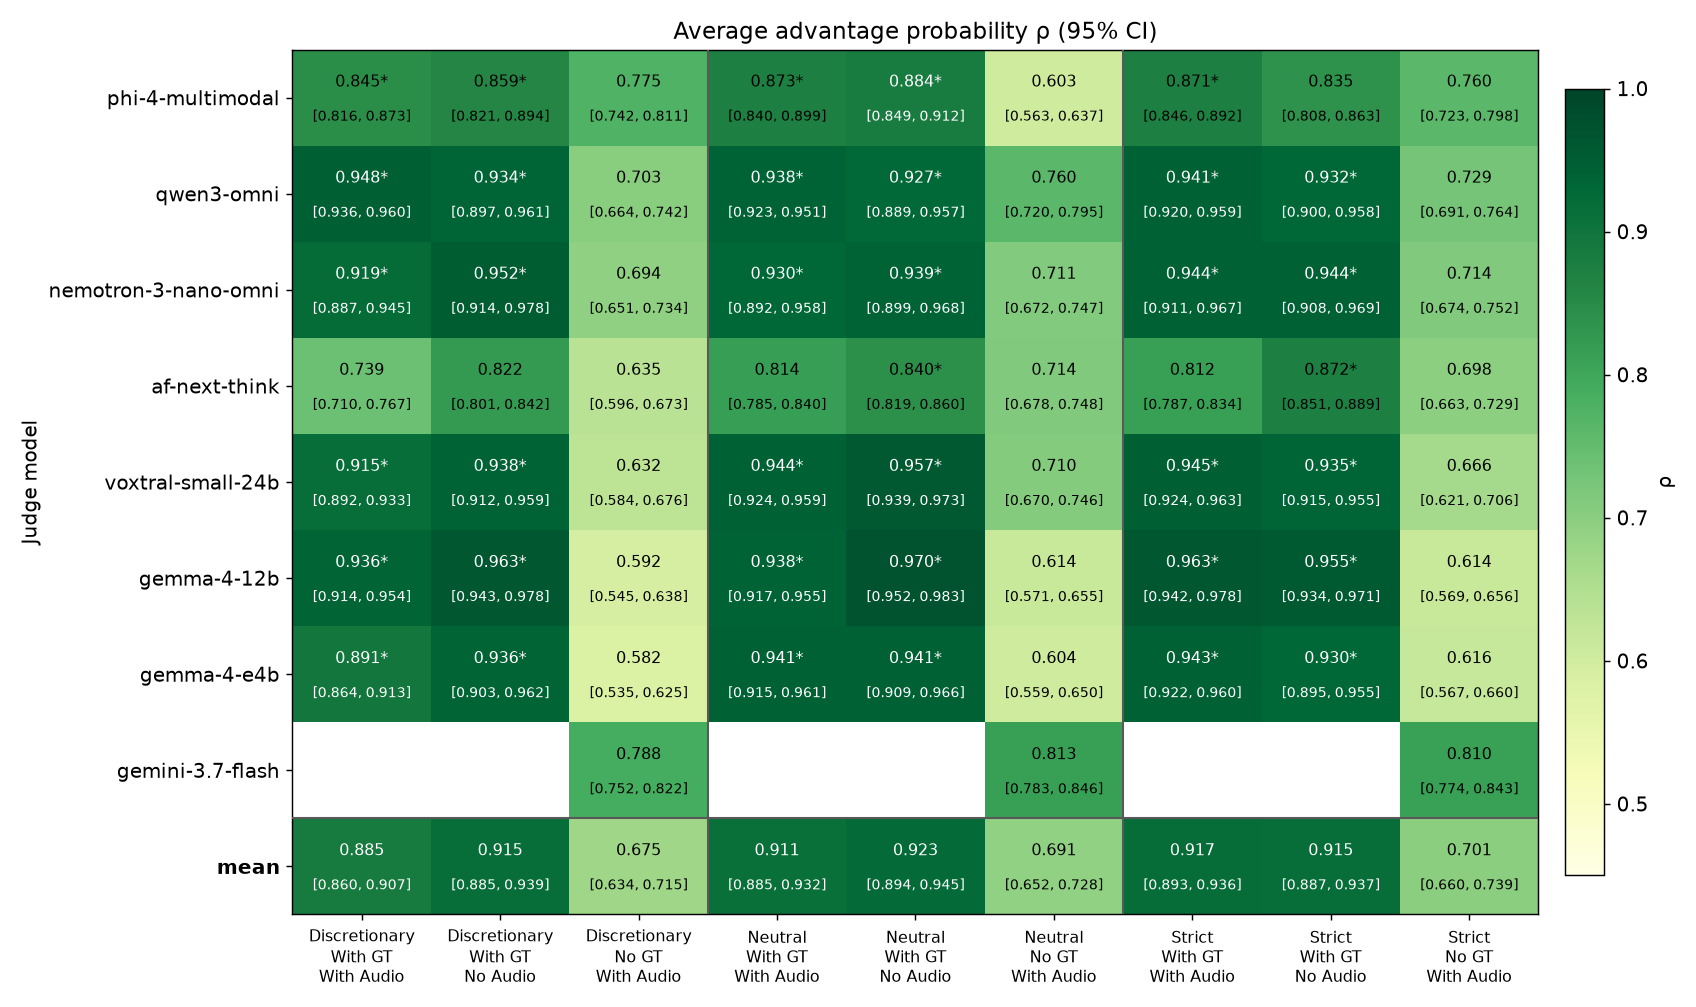

In [ ]:
rho = pivot("rho", HEATMAP_MODE_ORDER)
rho_lo = pivot("rho_lo", HEATMAP_MODE_ORDER)
rho_hi = pivot("rho_hi", HEATMAP_MODE_ORDER)
passed = pivot("passed", HEATMAP_MODE_ORDER)
heatmap_models = list(model_order)

# Gemini 3.7 Flash no-GT ρ is missing from the current pack; fill from a prior run.
GEMINI_ROW = "gemini-3.7-flash"
GEMINI_NO_GT_RHO = {
    "Discretionary": (0.788, 0.752, 0.822),
    "Neutral": (0.813, 0.783, 0.846),
    "Strict": (0.810, 0.774, 0.843),
}
if GEMINI_ROW not in rho.index:
    heatmap_models = [m for m in heatmap_models if m != GEMINI_ROW] + [GEMINI_ROW]
    rho = rho.reindex(heatmap_models)
    rho_lo = rho_lo.reindex(heatmap_models)
    rho_hi = rho_hi.reindex(heatmap_models)
    passed = passed.reindex(heatmap_models)
for style, (value, lo, hi) in GEMINI_NO_GT_RHO.items():
    mode = next(
        (
            m
            for m in HEATMAP_MODE_ORDER
            if (format_properties(m) or ("", "", ""))[:2] == (style, "No GT")
        ),
        None,
    )
    if mode is None or mode not in rho.columns:
        continue
    rho.loc[GEMINI_ROW, mode] = value
    rho_lo.loc[GEMINI_ROW, mode] = lo
    rho_hi.loc[GEMINI_ROW, mode] = hi

MEAN_ROW = "mean"
rho_plot = pd.concat([rho, rho.mean(axis=0, skipna=True).to_frame(MEAN_ROW).T])
rho_lo_plot = pd.concat([rho_lo, rho_lo.mean(axis=0, skipna=True).to_frame(MEAN_ROW).T])
rho_hi_plot = pd.concat([rho_hi, rho_hi.mean(axis=0, skipna=True).to_frame(MEAN_ROW).T])
passed_plot = pd.concat(
    [
        passed.reindex(index=rho.index, columns=rho.columns),
        pd.DataFrame(False, index=[MEAN_ROW], columns=rho.columns),
    ]
)
row_labels = list(heatmap_models) + [MEAN_ROW]

n_cols = len(HEATMAP_MODE_ORDER)
n_rows = len(row_labels)
fig, ax = plt.subplots(figsize=(max(10.5, 1.25 * n_cols + 1.8), 0.55 * n_rows + 2.8))
data = rho_plot.to_numpy(dtype=float)
lo_g = rho_lo_plot.to_numpy(dtype=float)
hi_g = rho_hi_plot.to_numpy(dtype=float)
passed_g = passed_plot.reindex(
    index=rho_plot.index, columns=rho_plot.columns
).to_numpy()
masked = np.ma.masked_invalid(data)
im = ax.imshow(masked, aspect="auto", cmap="YlGn", vmin=0.45, vmax=1.0)
ax.set_xticks(np.arange(n_cols))
ax.set_xticklabels(
    [format_axis_label(m) for m in HEATMAP_MODE_ORDER],
    ha="center",
    va="top",
    fontsize=9,
    linespacing=1.2,
)
ax.set_yticks(np.arange(n_rows))
ax.set_yticklabels(row_labels)
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.set_title("Average advantage probability ρ (95% CI)")
ax.set_xlabel("")
ax.set_ylabel("Judge model")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(True)
styles = [(format_properties(m) or ("", "", ""))[0] for m in HEATMAP_MODE_ORDER]
for j in range(1, n_cols):
    if styles[j] != styles[j - 1]:
        ax.axvline(j - 0.5, color="0.35", linewidth=1.15, zorder=3)
ax.axhline(len(heatmap_models) - 0.5, color="0.35", linewidth=1.15, zorder=3)

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        value = data[i, j]
        if np.isnan(value):
            continue
        star = "*" if passed_g[i, j] is True or passed_g[i, j] == True else ""
        ink = "white" if value >= 0.88 else "black"
        ax.text(
            j,
            i - 0.16,
            f"{value:.3f}{star}",
            ha="center",
            va="center",
            color=ink,
            fontsize=9,
        )
        lo, hi = lo_g[i, j], hi_g[i, j]
        if np.isfinite(lo) and np.isfinite(hi):
            ax.text(
                j,
                i + 0.20,
                f"[{lo:.3f}, {hi:.3f}]",
                ha="center",
                va="center",
                color=ink,
                fontsize=8,
            )

cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("ρ")
fig.tight_layout()
plt.show()


## With-GT audio vs no-audio (one-sided)

For each prompt style, under **With GT**, Δ = ρ(with audio) − ρ(no audio) on the shared instance ids. Question-clustered paired bootstrap; one-sided H₁: audio is worse. The 95% upper bound on Δ is the 0.95 quantile of Δ*. Audio is **significantly worse** when that bound is below 0 (equivalently *p* < 0.05, plus-one corrected). *p*-values are uncorrected across models × styles.


In [ ]:
WITH_GT_AUDIO_PAIRS = (
    ("Discretionary", "judge_with_gt", "judge_with_gt_no_audio"),
    ("Neutral", "neutral_with_gt", "neutral_with_gt_no_audio"),
    ("Strict", "with_gt_with_audio", "with_gt"),
)


def _judge_key_for(model: str, mode: str, key_mode: dict[str, str]) -> str | None:
    matches = [
        key
        for key, mapped in key_mode.items()
        if mapped == mode and parse_judge_key(key).get("model") == model
    ]
    return matches[0] if matches else None


def _instances_for_key(samples, key: str):
    return [
        (iid, ratings, _entry_correct((judges or {}).get(key)))
        for iid, ratings, judges in samples
    ]


labels_path = LOCAL_PACK_DIR / LABELS_CSV_NAME
_paired_rows = [
    row
    for row in triple_labeled_rows(load_pack_label_rows(labels_path))
    if not is_dropped_model(str(row.get("model_label") or ""))
]
pred_cache: dict[str, dict[str, dict]] = {}
samples = []
judge_keys: set[str] = set()
for row in _paired_rows:
    model = row["model_label"]
    qid = row["question_id"]
    if model not in pred_cache:
        pred_cache[model] = _load_predictions_by_id(
            LOCAL_PACK_DIR / "models" / model / "predictions.jsonl"
        )
    record = pred_cache[model].get(qid)
    shot = _shot_for_index(record, row["shot_index"]) if record else None
    judges = None
    if shot is not None and isinstance(shot.get("judges"), dict):
        judges = {
            str(key): dict(entry)
            for key, entry in shot["judges"].items()
            if key and not is_dropped_model(str(key))
        }
        judge_keys.update(judges)
    samples.append((_instance_id(row), dict(row["ratings_by_annotator"]), judges))

key_mode: dict[str, str] = {}
for key in sorted(judge_keys):
    if is_dropped_model(key):
        continue
    sample_entry = next(
        (
            (judges or {}).get(key)
            for _iid, _ratings, judges in samples
            if judges and key in judges
        ),
        None,
    )
    mode = _judge_mode_bucket(
        key, sample_entry if isinstance(sample_entry, dict) else None
    )
    if mode is None:
        continue
    key_mode[key] = mode

audio_delta_rows = []
for style, audio_mode, text_mode in WITH_GT_AUDIO_PAIRS:
    if audio_mode not in PACK_MODE_ORDER or text_mode not in PACK_MODE_ORDER:
        continue
    for model in model_order:
        key_a = _judge_key_for(str(model), audio_mode, key_mode)
        key_b = _judge_key_for(str(model), text_mode, key_mode)
        if not key_a or not key_b:
            continue
        stats = compare_binary_judges(
            _instances_for_key(samples, key_a),
            _instances_for_key(samples, key_b),
        )
        audio_delta_rows.append(
            {
                "model": model,
                "style": style,
                "rho_audio": stats["rho_a"],
                "rho_text": stats["rho_b"],
                "delta": stats["delta"],
                "delta_hi": stats["delta_hi"],
                "p_audio_worse": stats["p_a_worse"],
                "worse": stats["a_significantly_worse"],
                "n": stats["n"],
                "n_only_audio": stats["n_only_a"],
                "n_only_text": stats["n_only_b"],
            }
        )

audio_delta_df = pd.DataFrame(audio_delta_rows)
if audio_delta_df.empty:
    raise SystemExit("No With-GT audio/text pairs found")

n_sig = int(audio_delta_df["worse"].sum())
print(
    f"{n_sig}/{len(audio_delta_df)} (model, style) pairs: with-audio ρ significantly worse "
    f"(one-sided 95%, question-clustered paired bootstrap)"
)
unmatched = audio_delta_df["n_only_audio"] + audio_delta_df["n_only_text"]
if unmatched.max() > 0:
    print(
        f"max unpaired instances (audio-only + text-only): {int(unmatched.max())}"
    )

show = audio_delta_df.drop(columns=["n_only_audio", "n_only_text"])
display(
    show.style.format(
        {
            "rho_audio": "{:.3f}",
            "rho_text": "{:.3f}",
            "delta": "{:+.3f}",
            "delta_hi": "{:+.3f}",
            "p_audio_worse": "{:.3g}",
            "n": "{:.0f}",
        },
        na_rep="—",
    ).apply(
        lambda row: ["background-color: #f4c7c3"] * len(row) if row["worse"] else [""] * len(row),
        axis=1,
    )
)



## Parse success rate by judge and prompt

Share of stored judge answers with a pass/fail verdict. Same models, prompt columns, and figure size as ρ. An unparsed reply is scored as a disagreement in the Alt-Test, so a parse drop can look like a ρ drop.

The second line is the unparsed count. The bottom **mean** row is the unweighted average of the model parse rates.


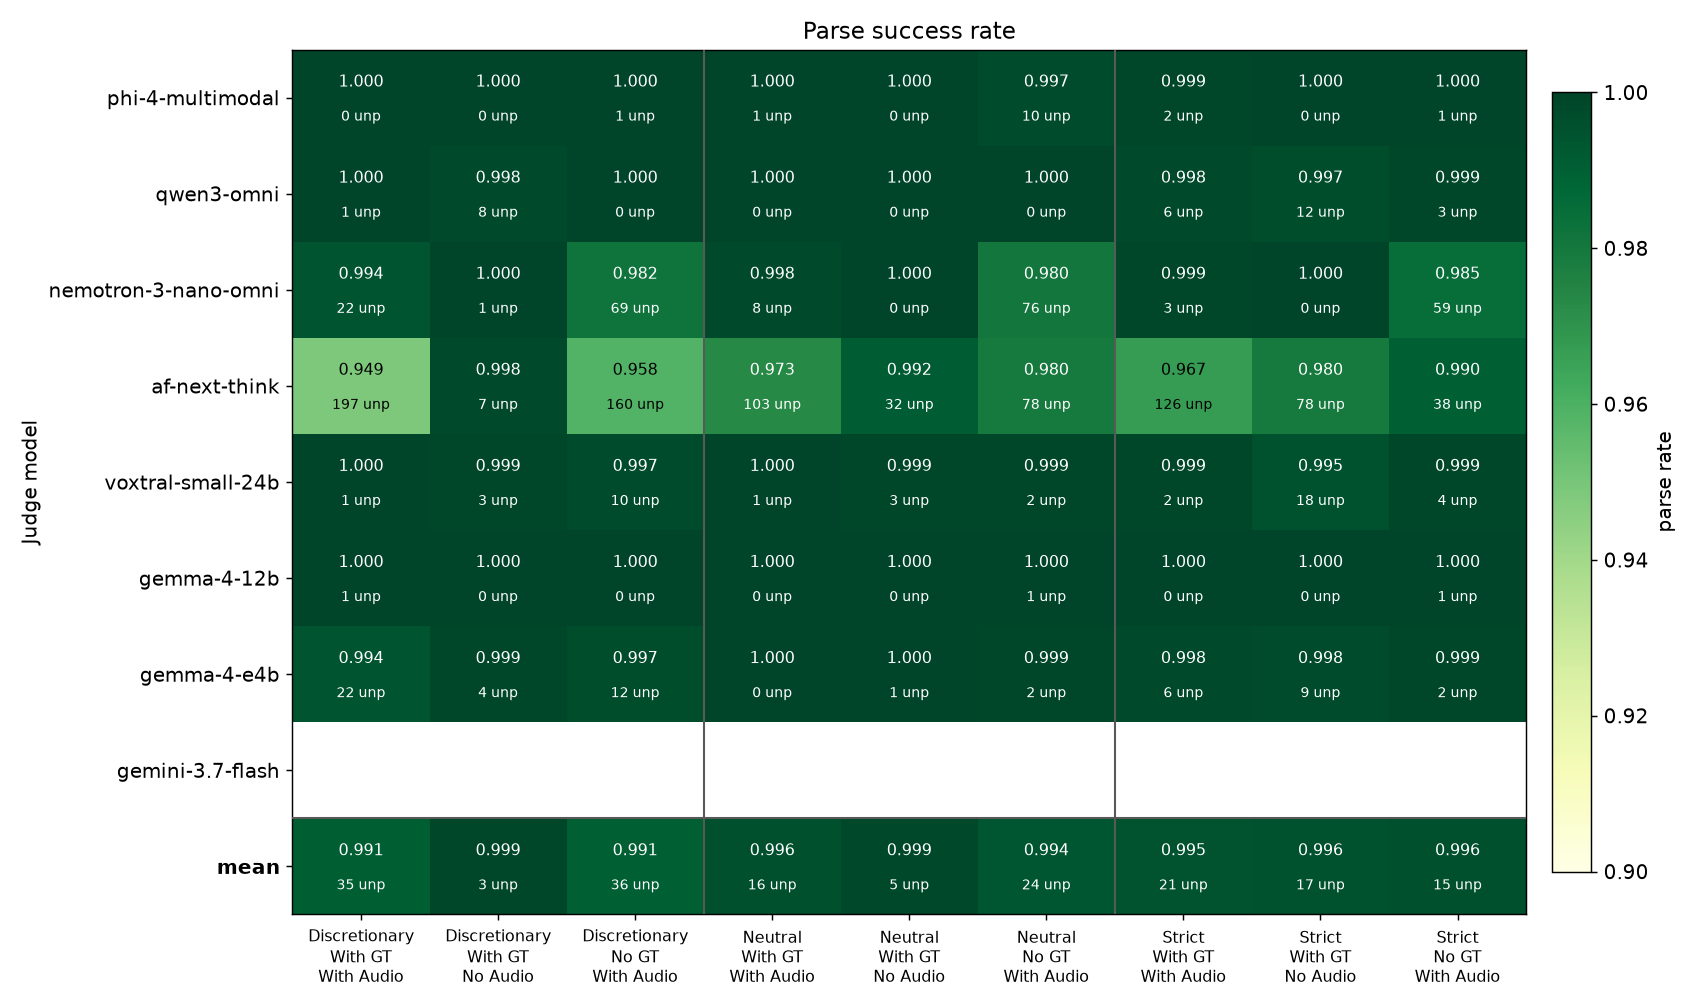

In [ ]:
parse = pivot("parse_rate", HEATMAP_MODE_ORDER)
unparsed = pivot("n_unparsed", HEATMAP_MODE_ORDER)
heatmap_models = list(model_order)

MEAN_ROW = "mean"
parse_plot = pd.concat([parse, parse.mean(axis=0, skipna=True).to_frame(MEAN_ROW).T])
unparsed_plot = pd.concat(
    [unparsed, unparsed.mean(axis=0, skipna=True).to_frame(MEAN_ROW).T]
)
row_labels = list(heatmap_models) + [MEAN_ROW]

n_cols = len(HEATMAP_MODE_ORDER)
n_rows = len(row_labels)
fig, ax = plt.subplots(figsize=(max(10.5, 1.25 * n_cols + 1.8), 0.55 * n_rows + 2.8))
data = parse_plot.to_numpy(dtype=float)
unp_g = unparsed_plot.to_numpy(dtype=float)
masked = np.ma.masked_invalid(data)
im = ax.imshow(masked, aspect="auto", cmap="YlGn", vmin=0.90, vmax=1.0)
ax.set_xticks(np.arange(n_cols))
ax.set_xticklabels(
    [format_axis_label(m) for m in HEATMAP_MODE_ORDER],
    ha="center",
    va="top",
    fontsize=9,
    linespacing=1.2,
)
ax.set_yticks(np.arange(n_rows))
ax.set_yticklabels(row_labels)
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.set_title("Parse success rate")
ax.set_xlabel("")
ax.set_ylabel("Judge model")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(True)
styles = [(format_properties(m) or ("", "", ""))[0] for m in HEATMAP_MODE_ORDER]
for j in range(1, n_cols):
    if styles[j] != styles[j - 1]:
        ax.axvline(j - 0.5, color="0.35", linewidth=1.15, zorder=3)
ax.axhline(len(heatmap_models) - 0.5, color="0.35", linewidth=1.15, zorder=3)

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        value = data[i, j]
        if np.isnan(value):
            continue
        ink = "white" if value >= 0.97 else "black"
        ax.text(
            j,
            i - 0.16,
            f"{value:.3f}",
            ha="center",
            va="center",
            color=ink,
            fontsize=9,
        )
        unp = unp_g[i, j]
        if np.isfinite(unp):
            ax.text(
                j,
                i + 0.20,
                f"{unp:.0f} unp",
                ha="center",
                va="center",
                color=ink,
                fontsize=8,
            )

cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("parse rate")
fig.tight_layout()
plt.show()


## Average labeler agreement

Each fully labeled shot has three human pass/fail ratings. Pairwise agreement is **1** when all three match and **⅓** on a 2–1 split (the same quantity as leave-one-out `hum` in the Alt-Test tables). The histogram is one value per question: that pairwise score averaged over every 3-rater shot of the question.


questions=142  shots=3834  mean pairwise=0.890  median=0.951  shots with a 2–1 split=630/3834 (16.4%)


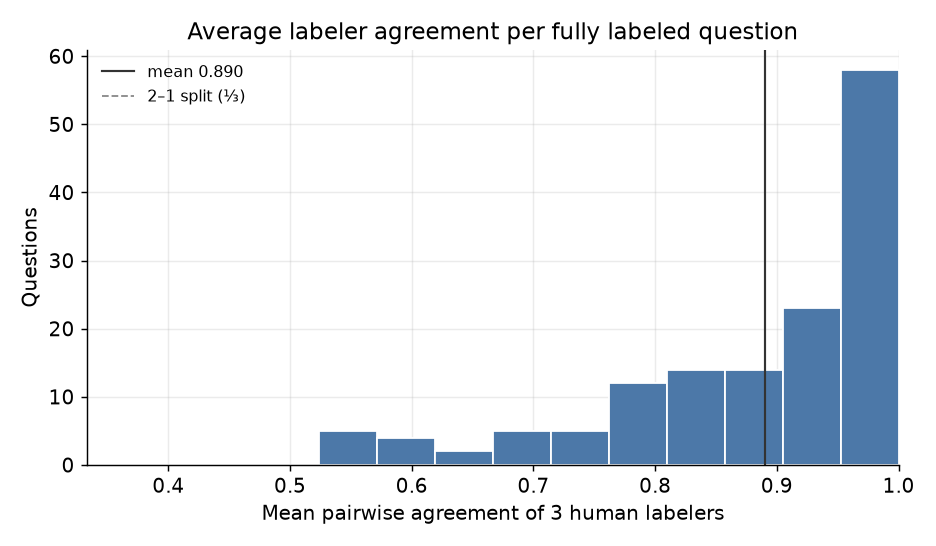

In [ ]:
from collections import defaultdict
from itertools import combinations


def pairwise_agreement(ratings: list[bool]) -> float:
    values = [bool(item) for item in ratings]
    pairs = list(combinations(values, 2))
    if not pairs:
        return float("nan")
    return float(np.mean([a == b for a, b in pairs]))


triple_rows = [
    row
    for row in load_pack_label_rows(LOCAL_PACK_DIR / LABELS_CSV_NAME)
    if len(row["ratings"]) >= 3
]
by_question: dict[str, list[float]] = defaultdict(list)
for row in triple_rows:
    by_question[row["question_id"]].append(pairwise_agreement(row["ratings"]))

q_agree = np.array([float(np.mean(scores)) for scores in by_question.values()])
inst_agree = np.array([score for scores in by_question.values() for score in scores])
n_split = int(np.sum(inst_agree < 1.0 - 1e-12))

print(
    f"questions={len(q_agree)}  shots={len(inst_agree)}  "
    f"mean pairwise={q_agree.mean():.3f}  median={np.median(q_agree):.3f}  "
    f"shots with a 2–1 split={n_split}/{len(inst_agree)} ({n_split / len(inst_agree):.1%})"
)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(
    q_agree,
    bins=np.linspace(1 / 3, 1.0, 15),
    color="#4C78A8",
    edgecolor="white",
)
ax.axvline(
    q_agree.mean(),
    color="#333333",
    linewidth=1.2,
    label=f"mean {q_agree.mean():.3f}",
)
ax.axvline(1 / 3, color="#888888", linewidth=1, linestyle="--", label="2–1 split (⅓)")
ax.set_xlabel("Mean pairwise agreement of 3 human labelers")
ax.set_ylabel("Questions")
ax.set_title("Average labeler agreement per fully labeled question")
ax.set_xlim(1 / 3, 1.0)
ax.legend(loc="upper left", fontsize=9, frameon=False)
fig.tight_layout()
plt.show()


## [GV Gap] Generation accuracy vs `neutral_no_gt` judging

For models in `exports/labels.csv`, generation accuracy is the fraction of **9** human ratings that are Correct (3 shots × 3 labelers). No model has three raters on every labeled generation — 27 questions have 1–2 ratings — so the mean uses the **142** questions where all three shots have all three ratings.

That score is correlated with the same model's **majority-agreement accuracy** as a `neutral_no_gt` judge (parsed verdict vs the three-human majority on the same 142 questions). Unparsed replies never match a human majority, so they count as disagreements. Models that lack either a complete denom-9 series or a `neutral_no_gt` judge slot are listed, not plotted. Dropped models (`DROPPED_MODEL_LABELS`) are omitted.


In [ ]:
from collections import defaultdict

from scipy.stats import pearsonr, spearmanr

from aggregate import is_dropped_model
from alt_test import majority_label

N_SHOTS = 3
N_LABELERS = 3
DENOM = N_SHOTS * N_LABELERS
JUDGE_MODE = "neutral_no_gt"

label_rows = [
    row
    for row in load_pack_label_rows(EXPORTS_DIR / LABELS_CSV_NAME)
    if not is_dropped_model(row["model_label"])
]
by_model_q: dict[str, dict[str, list]] = defaultdict(lambda: defaultdict(list))
for row in label_rows:
    by_model_q[row["model_label"]][row["question_id"]].append(row)

gen_rows = []
partial_models = []
for model, by_q in sorted(by_model_q.items()):
    full = []
    for items in by_q.values():
        if len(items) == N_SHOTS and all(len(item["ratings"]) == N_LABELERS for item in items):
            full.append(items)
    n_q = len(full)
    n_all_q = len(by_q)
    if n_q == 0:
        partial_models.append(model)
        continue
    n_true = sum(sum(item["ratings"]) for items in full for item in items)
    gen_rows.append(
        {
            "model": model,
            "n_questions": n_q,
            "n_partial_questions": n_all_q - n_q,
            "n_true": int(n_true),
            "gen_acc": n_true / (n_q * DENOM),
        }
    )

gen_df = pd.DataFrame(gen_rows)


def _load_judge_samples(pack_dir):
    pred_cache: dict[str, dict] = {}
    samples = []
    judge_keys: set[str] = set()
    for row in label_rows:
        model = row["model_label"]
        qid = row["question_id"]
        if model not in pred_cache:
            pred_cache[model] = _load_predictions_by_id(
                pack_dir / "models" / model / "predictions.jsonl"
            )
        record = pred_cache[model].get(qid)
        shot = _shot_for_index(record, row["shot_index"]) if record else None
        judges = None
        if shot is not None and isinstance(shot.get("judges"), dict):
            judges = {
                str(key): dict(entry)
                for key, entry in shot["judges"].items()
                if key and not is_dropped_model(str(key))
            }
            judge_keys.update(judges)
        samples.append((list(row["ratings"]), judges))
    key_mode = {}
    for key in sorted(judge_keys):
        sample_entry = next(
            (
                judges.get(key)
                for _ratings, judges in samples
                if judges and key in judges
            ),
            None,
        )
        mode = _judge_mode_bucket(
            key, sample_entry if isinstance(sample_entry, dict) else None
        )
        if mode is not None:
            key_mode[key] = mode
    return samples, key_mode


if "samples" in globals() and "key_mode" in globals():
    judge_samples = [
        (ratings, judges) for _iid, ratings, judges in samples
    ]
    judge_key_mode = {
        key: mode
        for key, mode in key_mode.items()
        if not is_dropped_model(key)
    }
else:
    judge_samples, judge_key_mode = _load_judge_samples(LOCAL_PACK_DIR)

nng_keys = [key for key, mode in judge_key_mode.items() if mode == JUDGE_MODE]
judge_rows = []
for key in sorted(nng_keys):
    model = parse_judge_key(key).get("model") or key
    n = 0
    n_agree = 0
    n_parsed = 0
    n_parsed_agree = 0
    n_unparsed = 0
    for ratings, judges in judge_samples:
        if len(ratings) < N_LABELERS:
            continue
        rating_values = list(ratings.values()) if isinstance(ratings, dict) else ratings
        gold = majority_label(rating_values)
        if gold is None:
            continue
        entry = (judges or {}).get(key)
        pred = _entry_correct(entry) if isinstance(entry, dict) else None
        if pred is None:
            continue
        n += 1
        if isinstance(pred, bool):
            n_parsed += 1
            if pred == gold:
                n_agree += 1
                n_parsed_agree += 1
        else:
            n_unparsed += 1
    judge_rows.append(
        {
            "model": model,
            "n_judge": n,
            "n_unparsed": n_unparsed,
            "judge_acc": (n_agree / n) if n else None,
            "judge_acc_parsed": (n_parsed_agree / n_parsed) if n_parsed else None,
        }
    )

judge_df = pd.DataFrame(judge_rows)
alt = df.loc[df["mode"] == JUDGE_MODE, ["model", "llm", "rho", "parse_rate"]].copy()
alt["model"] = alt["model"].astype(str)
corr_df = gen_df.merge(judge_df, on="model", how="inner").merge(alt, on="model", how="left")
corr_df = corr_df.sort_values("gen_acc").reset_index(drop=True)

labeled_models = set(gen_df["model"])
nng_models = set(judge_df["model"]) if len(judge_df) else set()
print(
    f"denom-9 questions: {int(gen_df['n_questions'].iloc[0]) if len(gen_df) else 0} "
    f"(dropped {int(gen_df['n_partial_questions'].iloc[0]) if len(gen_df) else 0} with <3 raters)"
)
print(f"models with denom-9 series: {len(labeled_models)}")
print(f"models with {JUDGE_MODE} verdicts: {len(nng_models)}")
print(
    "labeled, no "
    f"{JUDGE_MODE}: {', '.join(sorted(labeled_models - nng_models)) or '—'}"
)
print(
    f"{JUDGE_MODE}, no labels: {', '.join(sorted(nng_models - labeled_models)) or '—'}"
)
if partial_models:
    print(f"no complete denom-9 series: {', '.join(partial_models)}")

if len(corr_df) < 2:
    raise SystemExit("Need at least two models with both scores")

r_pearson, p_pearson = pearsonr(corr_df["gen_acc"], corr_df["judge_acc"])
r_spearman, p_spearman = spearmanr(corr_df["gen_acc"], corr_df["judge_acc"])
print(
    f"\nPearson r = {r_pearson:.3f} (p = {p_pearson:.3f})  "
    f"Spearman ρ = {r_spearman:.3f} (p = {p_spearman:.3f})  "
    f"n = {len(corr_df)}"
)

display(
    corr_df[
        [
            "model",
            "n_questions",
            "n_true",
            "gen_acc",
            "n_judge",
            "n_unparsed",
            "judge_acc",
            "judge_acc_parsed",
            "llm",
            "rho",
            "parse_rate",
        ]
    ].style.format(
        {
            "gen_acc": "{:.3f}",
            "judge_acc": "{:.3f}",
            "judge_acc_parsed": "{:.3f}",
            "llm": "{:.3f}",
            "rho": "{:.3f}",
            "parse_rate": "{:.3f}",
        },
        na_rep="—",
    )
)


denom-9 questions: 142 (dropped 27 with <3 raters)
models with denom-9 series: 9
models with neutral_no_gt verdicts: 7
labeled, no neutral_no_gt: gemini-3.7-flash, interactive-omni-8b, mimo-audio-7b, qwen3-omni-instruct
neutral_no_gt, no labels: gemma-4-12b, nemotron-3-nano-omni

Pearson r = 0.842 (p = 0.074)  Spearman ρ = 0.900 (p = 0.037)  n = 5


,model,n_questions,n_true,gen_acc,n_judge,n_unparsed,judge_acc,judge_acc_parsed,llm,rho,parse_rate
0,phi-4-multimodal,142,237,0.185,3834,10,0.492,0.493,0.519,0.603,0.997
1,gemma-4-e4b,142,296,0.232,3834,2,0.506,0.506,0.521,0.604,0.999
2,af-next-think,142,316,0.247,3834,78,0.622,0.635,0.628,0.714,0.980
3,voxtral-small-24b,142,410,0.321,3834,2,0.612,0.612,0.626,0.710,0.999
4,qwen3-omni,142,584,0.457,3834,0,0.670,0.670,0.676,0.760,1.000


## Within-model, per-question: can it answer, and can it judge?

The previous scatter is one point per model. Here each point is a **question**. For model *m* on question *q*, generation accuracy is again the fraction of 9 human ratings that are Correct. Judge accuracy is *m*'s `neutral_no_gt` majority-agreement on the **other** models' labeled shots for that same question (the model's own three shots are dropped so “I got this right” is not mixed with “I graded myself correctly”).

“Can answer” is `gen_acc > 0.5` (at least five of the nine ratings True). Same 142-question, five-model intersection as above.


In [ ]:
from collections import defaultdict

from scipy.stats import pearsonr, spearmanr, ttest_ind

from aggregate import is_dropped_model
from alt_test import majority_label

if "N_SHOTS" not in globals():
    N_SHOTS, N_LABELERS, DENOM = 3, 3, 9
    JUDGE_MODE = "neutral_no_gt"
if "label_rows" not in globals():
    label_rows = [
        row
        for row in load_pack_label_rows(EXPORTS_DIR / LABELS_CSV_NAME)
        if not is_dropped_model(row["model_label"])
    ]
elif any(is_dropped_model(row["model_label"]) for row in label_rows):
    label_rows = [row for row in label_rows if not is_dropped_model(row["model_label"])]


def _complete_questions(rows):
    by_mq = defaultdict(lambda: defaultdict(list))
    for row in rows:
        by_mq[row["model_label"]][row["question_id"]].append(row)
    complete = None
    for by_q in by_mq.values():
        qs = {
            qid
            for qid, items in by_q.items()
            if len(items) == N_SHOTS
            and all(len(item["ratings"]) == N_LABELERS for item in items)
        }
        complete = qs if complete is None else complete & qs
    return by_mq, complete or set()


def _iter_judge_rows(rows, pack_dir):
    if "samples" in globals() and samples:
        first = samples[0]
        if len(first) == 3 and isinstance(first[0], str) and "\t" in first[0]:
            for iid, ratings, judges in samples:
                qid, gradee, shot_s = str(iid).split("\t")
                rating_values = list(ratings.values()) if isinstance(ratings, dict) else list(ratings)
                yield qid, gradee, int(shot_s), rating_values, judges
            return
    pred_cache: dict[str, dict] = {}
    for row in rows:
        model = row["model_label"]
        qid = row["question_id"]
        if model not in pred_cache:
            pred_cache[model] = _load_predictions_by_id(
                pack_dir / "models" / model / "predictions.jsonl"
            )
        record = pred_cache[model].get(qid)
        shot = _shot_for_index(record, row["shot_index"]) if record else None
        judges = None
        if shot is not None and isinstance(shot.get("judges"), dict):
            judges = {
                str(key): dict(entry)
                for key, entry in shot["judges"].items()
                if key
            }
        yield qid, model, row["shot_index"], list(row["ratings"]), judges


def _nng_keys(judge_rows):
    if "judge_key_mode" in globals():
        return [key for key, mode in judge_key_mode.items() if mode == JUDGE_MODE]
    if "key_mode" in globals():
        return [key for key, mode in key_mode.items() if mode == JUDGE_MODE]
    keys = set()
    for *_, judges in judge_rows:
        if judges:
            keys.update(judges)
    out = []
    for key in sorted(keys):
        sample_entry = next(
            (judges.get(key) for *_, judges in judge_rows if judges and key in judges),
            None,
        )
        mode = _judge_mode_bucket(
            key, sample_entry if isinstance(sample_entry, dict) else None
        )
        if mode == JUDGE_MODE:
            out.append(key)
    return out


by_mq, complete_q = _complete_questions(label_rows)
judge_iter = list(_iter_judge_rows(label_rows, LOCAL_PACK_DIR))
nng_keys_q = _nng_keys(judge_iter)

gen_acc_q = {}
for model, by_q in by_mq.items():
    for qid in complete_q:
        items = by_q[qid]
        n_true = sum(sum(item["ratings"]) for item in items)
        gen_acc_q[(model, qid)] = n_true / DENOM

q_rows = []
for key in sorted(nng_keys_q):
    judge_model = parse_judge_key(key).get("model") or key
    if judge_model not in by_mq:
        continue
    by_q_stats = defaultdict(lambda: dict(n=0, agree=0, n_oth=0, agree_oth=0))
    for qid, gradee, _shot, ratings, judges in judge_iter:
        if qid not in complete_q:
            continue
        gold = majority_label(ratings)
        if gold is None:
            continue
        pred = (
            _entry_correct((judges or {}).get(key))
            if judges and key in (judges or {})
            else None
        )
        if pred is None:
            continue
        correct = isinstance(pred, bool) and pred == gold
        st = by_q_stats[qid]
        st["n"] += 1
        st["agree"] += int(correct)
        if gradee != judge_model:
            st["n_oth"] += 1
            st["agree_oth"] += int(correct)
    for qid, st in by_q_stats.items():
        q_rows.append(
            {
                "model": judge_model,
                "question_id": qid,
                "gen_acc": gen_acc_q[(judge_model, qid)],
                "judge_acc": (st["agree"] / st["n"]) if st["n"] else np.nan,
                "judge_acc_others": (
                    (st["agree_oth"] / st["n_oth"]) if st["n_oth"] else np.nan
                ),
                "n_judge": st["n"],
                "n_others": st["n_oth"],
                "can_answer": gen_acc_q[(judge_model, qid)] > 0.5,
            }
        )

q_df = pd.DataFrame(q_rows)
if q_df.empty:
    raise SystemExit("No per-question judge/generation pairs")

per_model = []
for model, sub in q_df.groupby("model", sort=True):
    s = sub.dropna(subset=["gen_acc", "judge_acc_others"])
    r, p = pearsonr(s["gen_acc"], s["judge_acc_others"])
    rs, ps = spearmanr(s["gen_acc"], s["judge_acc_others"])
    r_all, p_all = pearsonr(s["gen_acc"], s["judge_acc"])
    can = s.loc[s["can_answer"], "judge_acc_others"]
    cant = s.loc[~s["can_answer"], "judge_acc_others"]
    t_stat, t_p = ttest_ind(can, cant, equal_var=False) if len(can) and len(cant) else (np.nan, np.nan)
    per_model.append(
        {
            "model": model,
            "n_questions": len(s),
            "n_can": int(len(can)),
            "n_cant": int(len(cant)),
            "r": r,
            "p": p,
            "spearman": rs,
            "spearman_p": ps,
            "r_incl_self": r_all,
            "judge_can": float(can.mean()) if len(can) else np.nan,
            "judge_cant": float(cant.mean()) if len(cant) else np.nan,
            "delta": (
                float(can.mean() - cant.mean()) if len(can) and len(cant) else np.nan
            ),
            "ttest_p": t_p,
        }
    )

per_model_df = pd.DataFrame(per_model)
pooled = q_df.dropna(subset=["gen_acc", "judge_acc_others"])
r_pool, p_pool = pearsonr(pooled["gen_acc"], pooled["judge_acc_others"])
rs_pool, ps_pool = spearmanr(pooled["gen_acc"], pooled["judge_acc_others"])
print(
    f"per-question pairs: {len(q_df)}  models: {q_df['model'].nunique()}  "
    f"questions: {q_df['question_id'].nunique()}"
)
print(
    f"pooled (exclude self) Pearson r = {r_pool:.3f} (p = {p_pool:.3g})  "
    f"Spearman ρ = {rs_pool:.3f} (p = {ps_pool:.3g})"
)
print("judge_acc_others = majority agreement on other models' shots for that question")

display(
    per_model_df.style.format(
        {
            "r": "{:.3f}",
            "p": "{:.3g}",
            "spearman": "{:.3f}",
            "spearman_p": "{:.3g}",
            "r_incl_self": "{:.3f}",
            "judge_can": "{:.3f}",
            "judge_cant": "{:.3f}",
            "delta": "{:+.3f}",
            "ttest_p": "{:.3g}",
        },
        na_rep="—",
    )
)


per-question pairs: 710  models: 5  questions: 142
pooled (exclude self) Pearson r = 0.458 (p = 3.99e-38)  Spearman ρ = 0.443 (p = 2.11e-35)
judge_acc_others = majority agreement on other models' shots for that question


,model,n_questions,n_can,n_cant,r,p,spearman,spearman_p,r_incl_self,judge_can,judge_cant,delta,ttest_p
0,af-next-think,142,27,115,0.273,0.000998,0.224,0.0073,0.341,0.750,0.613,+0.137,0.0101
1,gemma-4-e4b,142,26,116,0.401,7.85e-07,0.379,3.36e-06,0.464,0.705,0.478,+0.227,0.000331
2,phi-4-multimodal,142,23,119,0.563,2.88e-13,0.505,1.51e-10,0.598,0.788,0.445,+0.343,9.15e-09
3,qwen3-omni,142,67,75,0.441,4.03e-08,0.463,6.63e-09,0.515,0.765,0.615,+0.150,1.55e-06
4,voxtral-small-24b,142,40,102,0.436,6e-08,0.406,5.38e-07,0.451,0.749,0.562,+0.187,6.18e-05


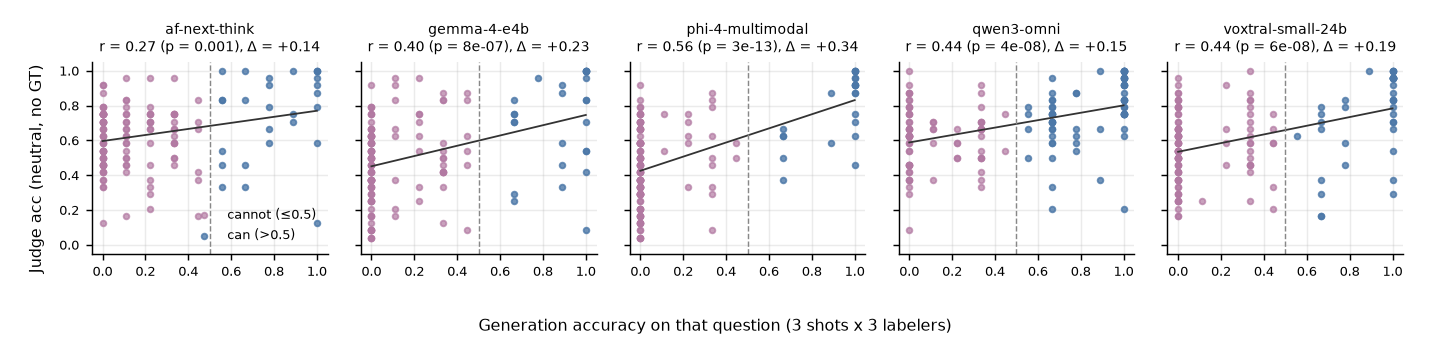

In [ ]:
models = list(per_model_df["model"])
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(2.2 * n_models, 2.6), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
for ax, model in zip(axes, models):
    sub = q_df[q_df["model"] == model].dropna(subset=["gen_acc", "judge_acc_others"])
    x = sub["gen_acc"].to_numpy(dtype=float)
    y = sub["judge_acc_others"].to_numpy(dtype=float)
    can = sub["can_answer"].to_numpy(dtype=bool)
    ax.scatter(x[~can], y[~can], s=10, color="#B279A2", alpha=0.7, label="cannot (≤0.5)")
    ax.scatter(x[can], y[can], s=10, color="#4C78A8", alpha=0.8, label="can (>0.5)")
    if len(sub) >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        xs = np.linspace(0, 1, 40)
        ax.plot(xs, slope * xs + intercept, color="#333333", linewidth=1)
    row = per_model_df.set_index("model").loc[model]
    ax.set_title(f"{model}\nr = {row['r']:.2f} (p = {row['p']:.1g}), Δ = {row['delta']:+.2f}", fontsize=8)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.axvline(0.5, color="#888888", linewidth=0.8, linestyle="--")
    ax.tick_params(labelsize=7)
for ax in axes[n_models:]:
    ax.set_visible(False)
axes[0].legend(loc="lower right", fontsize=7, frameon=False)
fig.supxlabel("Generation accuracy on that question (3 shots x 3 labelers)", fontsize=9)
fig.supylabel("Judge acc (neutral, no GT)", fontsize=9)
fig.tight_layout()
plt.show()
